In [54]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.naive_bayes import GaussianNB
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report
)

In [56]:
df = pd.read_csv("glass - glass.csv")

In [57]:
print("First five records:")
print(df.head())

print("\nLast five records:")
print(df.tail())

print("\nDataset Shape:")
print(df.shape)

print("\nColumn Names:")
print(df.columns.tolist())

print("\nDataset Information:")
df.info()

print("\nStatistical Summary:")
print(df.describe())

print("\nMissing Values:")
print(df.isnull().sum())

print("\nDuplicate Records:")
print(df.duplicated().sum())

First five records:
        RI     Na    Mg    Al     Si     K    Ca   Ba   Fe  Type
0  1.52101  13.64  4.49  1.10  71.78  0.06  8.75  0.0  0.0     1
1  1.51761  13.89  3.60  1.36  72.73  0.48  7.83  0.0  0.0     1
2  1.51618  13.53  3.55  1.54  72.99  0.39  7.78  0.0  0.0     1
3  1.51766  13.21  3.69  1.29  72.61  0.57  8.22  0.0  0.0     1
4  1.51742  13.27  3.62  1.24  73.08  0.55  8.07  0.0  0.0     1

Last five records:
          RI     Na   Mg    Al     Si     K    Ca    Ba   Fe  Type
209  1.51623  14.14  0.0  2.88  72.61  0.08  9.18  1.06  0.0     7
210  1.51685  14.92  0.0  1.99  73.06  0.00  8.40  1.59  0.0     7
211  1.52065  14.36  0.0  2.02  73.42  0.00  8.44  1.64  0.0     7
212  1.51651  14.38  0.0  1.94  73.61  0.00  8.48  1.57  0.0     7
213  1.51711  14.23  0.0  2.08  73.36  0.00  8.62  1.67  0.0     7

Dataset Shape:
(214, 10)

Column Names:
['RI', 'Na', 'Mg', 'Al', 'Si', 'K', 'Ca', 'Ba', 'Fe', 'Type']

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
Range


Glass Type Distribution:
Type
1    70
2    76
3    17
5    13
6     9
7    29
Name: count, dtype: int64


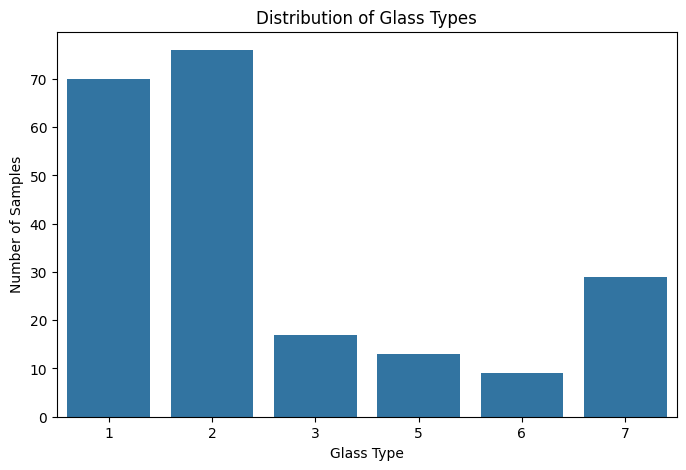

In [58]:
print("\nGlass Type Distribution:")
print(df["Type"].value_counts().sort_index())

plt.figure(figsize=(8, 5))
sns.countplot(data=df, x="Type")
plt.title("Distribution of Glass Types")
plt.xlabel("Glass Type")
plt.ylabel("Number of Samples")
plt.show()


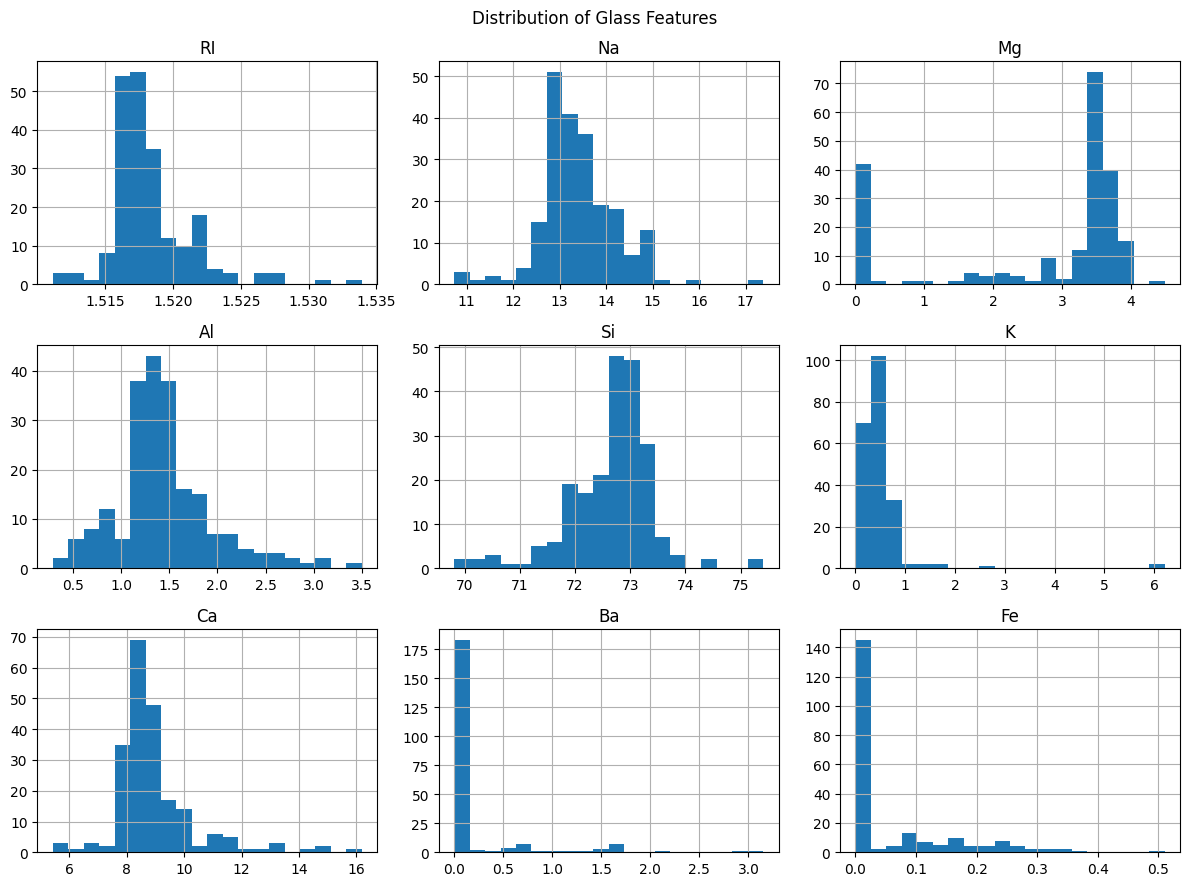

In [59]:
feature_cols = [
    "RI", "Na", "Mg", "Al", "Si",
    "K", "Ca", "Ba", "Fe"
]

df[feature_cols].hist(figsize=(12, 9), bins=20)
plt.suptitle("Distribution of Glass Features")
plt.tight_layout()
plt.show()

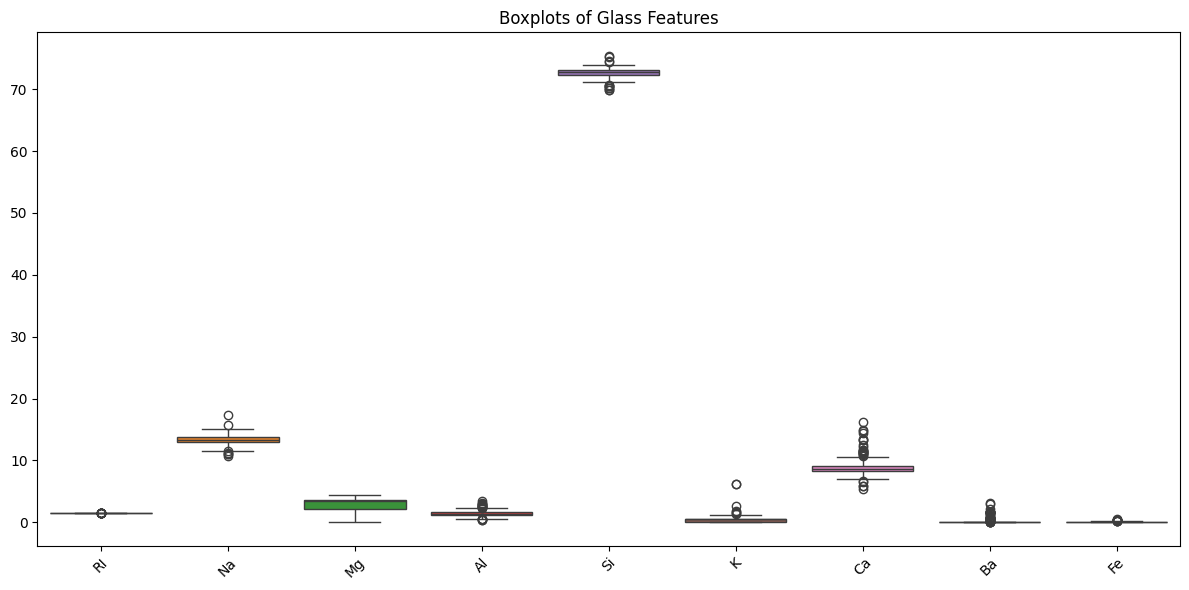

In [60]:
plt.figure(figsize=(12, 6))
sns.boxplot(data=df[feature_cols])
plt.title("Boxplots of Glass Features")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

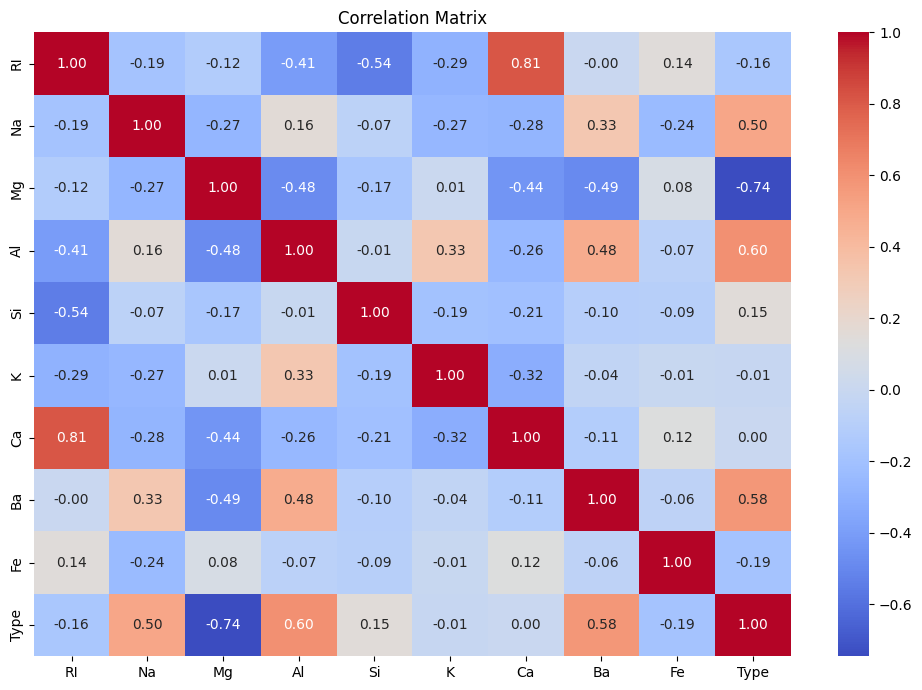

In [61]:
plt.figure(figsize=(10, 7))
sns.heatmap(
    df.corr(numeric_only=True),
    annot=True,
    fmt=".2f",
    cmap="coolwarm"
)
plt.title("Correlation Matrix")
plt.tight_layout()
plt.show()

In [63]:
X = df[feature_cols]
y = df["Type"]

# Handle missing values if present
X = X.fillna(X.median())


In [64]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("\nTraining samples:", len(X_train))
print("Testing samples:", len(X_test))



Training samples: 171
Testing samples: 43


In [65]:
model = GaussianNB()
model.fit(X_train, y_train)

print("\nGaussian Naive Bayes model trained successfully.")


Gaussian Naive Bayes model trained successfully.


In [66]:
y_pred = model.predict(X_test)

print("\nActual Labels (first 10):")
print(y_test.to_numpy()[:10])

print("\nPredicted Labels (first 10):")
print(y_pred[:10])



Actual Labels (first 10):
[7 5 2 5 1 1 2 2 1 1]

Predicted Labels (first 10):
[7 2 1 5 1 1 1 2 1 1]



Confusion Matrix:
[[12  1  1  0  0  0]
 [ 9  2  1  0  2  1]
 [ 3  0  0  0  0  0]
 [ 0  2  0  1  0  0]
 [ 0  0  0  0  2  0]
 [ 0  0  0  1  0  5]]


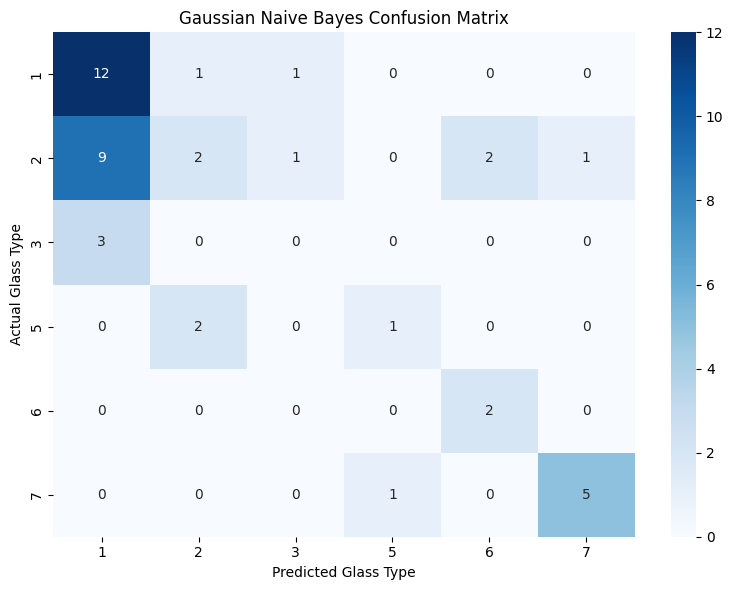

In [67]:
labels = sorted(y.unique())
cm = confusion_matrix(y_test, y_pred, labels=labels)

print("\nConfusion Matrix:")
print(cm)

plt.figure(figsize=(8, 6))
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=labels,
    yticklabels=labels
)
plt.title("Gaussian Naive Bayes Confusion Matrix")
plt.xlabel("Predicted Glass Type")
plt.ylabel("Actual Glass Type")
plt.tight_layout()
plt.show()

In [68]:
accuracy = accuracy_score(y_test, y_pred)
precision = precision_score(
    y_test, y_pred, average="weighted", zero_division=0
)
recall = recall_score(
    y_test, y_pred, average="weighted", zero_division=0
)
f1 = f1_score(
    y_test, y_pred, average="weighted", zero_division=0
)

print("\nModel Evaluation")
print(f"Accuracy  : {accuracy:.4f} ({accuracy * 100:.2f}%)")
print(f"Precision : {precision:.4f}")
print(f"Recall    : {recall:.4f}")
print(f"F1-score  : {f1:.4f}")

print("\nClassification Report:")
print(classification_report(
    y_test, y_pred, labels=labels, zero_division=0
))


Model Evaluation
Accuracy  : 0.5116 (51.16%)
Precision : 0.4767
Recall    : 0.5116
F1-score  : 0.4506

Classification Report:
              precision    recall  f1-score   support

           1       0.50      0.86      0.63        14
           2       0.40      0.13      0.20        15
           3       0.00      0.00      0.00         3
           5       0.50      0.33      0.40         3
           6       0.50      1.00      0.67         2
           7       0.83      0.83      0.83         6

    accuracy                           0.51        43
   macro avg       0.46      0.53      0.46        43
weighted avg       0.48      0.51      0.45        43

